# Exploración de datos MiBici

Objetivo: Explorar los datos procesados de MiBici para comprender su cobertura temporal, distribución de viajes y características de las estaciones antes de la construcción de variables y modelos predictivos.

Periodo analizado: 2025-10-01 a 2026-09-30


In [3]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT= r"C:\Users\stefa\TC5061-Proyecto-Equipo39"

os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from mibici_equipo39 import config as C

plt.style.use("default")
pd.set_option("display.max_columns", None)

In [5]:
arrivals = pd.read_parquet(
    C.INTERIM_DATA_DIR / "arrivals"
)

departures = pd.read_parquet(
    C.INTERIM_DATA_DIR / "departures"
)

In [6]:
arrivals.head()
departures.head()

,trip_id,station_id,timestamp,month
0,41060015,244,2025-10-01 00:00:26,2025-10
1,41060016,31,2025-10-01 00:00:31,2025-10
2,41060017,73,2025-10-01 00:00:36,2025-10
3,41060018,21,2025-10-01 00:00:37,2025-10
4,41060026,81,2025-10-01 00:02:38,2025-10


In [7]:
print("Departures")

print(
    departures["timestamp"].min(),
    departures["timestamp"].max()
)

print("\nArrivals")

print(
    arrivals["timestamp"].min(),
    arrivals["timestamp"].max()
)

Departures
2025-10-01 00:00:26 2026-09-30 23:59:48

Arrivals
2025-10-01 00:07:03 2026-10-01 00:14:52


C:\Users\stefa\AppData\Local\Temp\ipykernel_25828\3237009756.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("month")


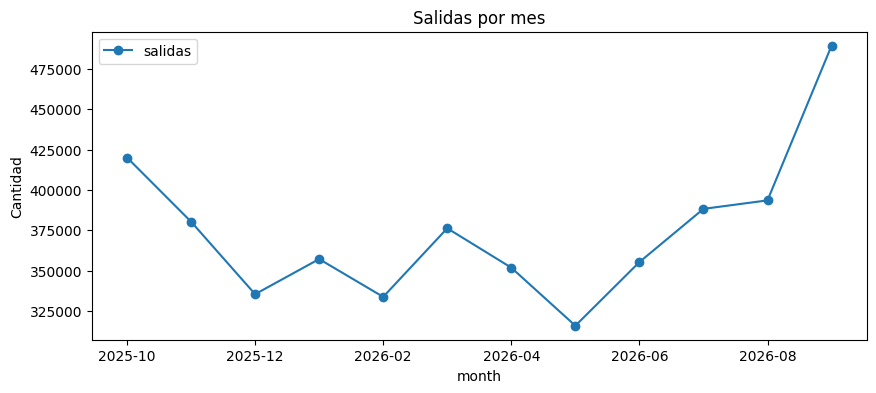

In [8]:
# Departures
departures_per_month = (
    departures
    .groupby("month")
    .size()
    .reset_index(name="salidas")
)

departures_per_month

departures_per_month.plot(
    x="month",
    y="salidas",
    figsize=(10,4),
    marker="o"
)

plt.title("Salidas por mes")
plt.ylabel("Cantidad")
plt.show()

C:\Users\stefa\AppData\Local\Temp\ipykernel_25828\3615620195.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("month")


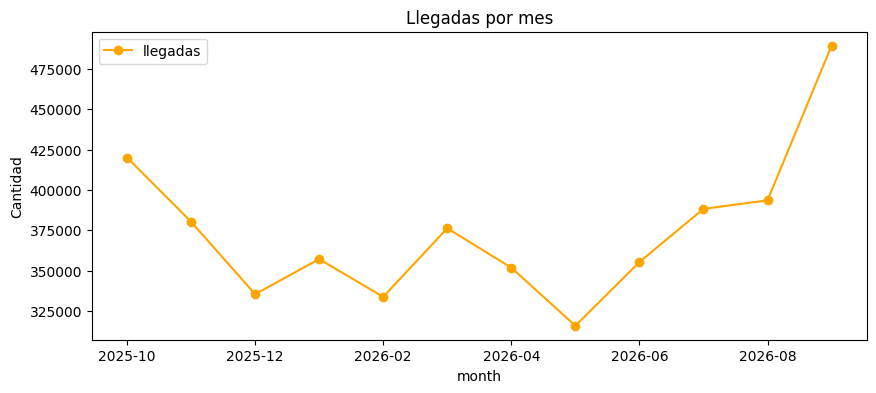

In [9]:
# Arrivals

arrivals_per_month = (
    arrivals
    .groupby("month")
    .size()
    .reset_index(name="llegadas")
)

arrivals_per_month

arrivals_per_month.plot(
    x="month",
    y="llegadas",
    figsize=(10,4),
    marker="o",
    color="orange"
)

plt.title("Llegadas por mes")
plt.ylabel("Cantidad")
plt.show()

## Conteos por mes

La cantidad de viajes presenta variaciones entre meses. Septiembre de 2026 muestra el mayor número de registros válidos, mientras que algunos meses invernales presentan menor actividad. Esto sugiere un posible efecto estacional que deberá considerarse durante el modelado.

In [11]:
# Dias con informacion
departures["date"] = (
    pd.to_datetime(departures["timestamp"])
      .dt.date
)

days_per_month = (
    departures
    .groupby("month")["date"]
    .nunique()
    .reset_index(name="dias_con_informacion")
)

days_per_month

C:\Users\stefa\AppData\Local\Temp\ipykernel_25828\615767541.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("month")["date"]


,month,dias_con_informacion
0,2025-10,31
1,2025-11,30
2,2025-12,31
3,2026-01,31
4,2026-02,28
5,2026-03,31
6,2026-04,30
7,2026-05,31
8,2026-06,30
9,2026-07,31


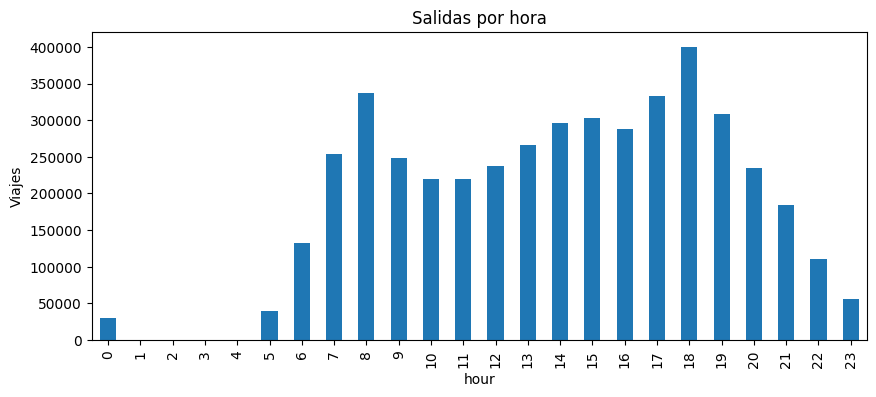

In [12]:
# Salidas por hora
departures["hour"] = (
    pd.to_datetime(departures["timestamp"])
      .dt.hour
)

departures_hour = (
    departures
    .groupby("hour")
    .size()
)

departures_hour.plot(
    kind="bar",
    figsize=(10,4)
)

plt.title("Salidas por hora")
plt.ylabel("Viajes")
plt.show()

## Salidas por hora

La demanda muestra patrones horarios definidos. Se observan horas pico que justifican la incorporación de variables temporales como hora del día y transformaciones cíclicas (hour_sin, hour_cos).

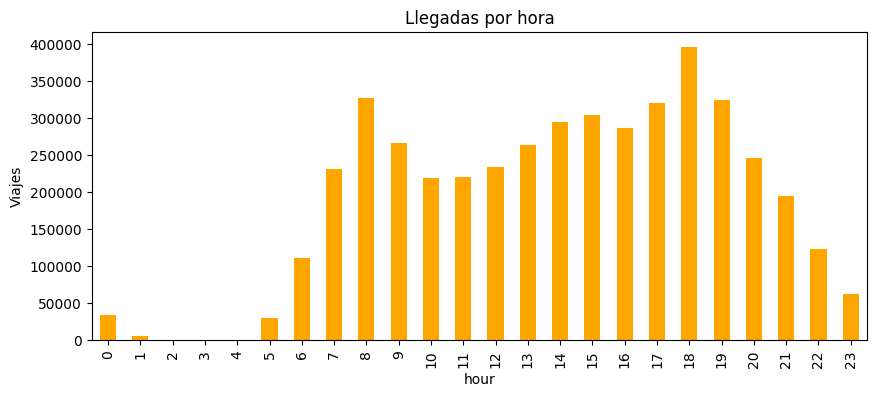

In [13]:
# Llegadas por hora

arrivals["hour"] = (
    pd.to_datetime(arrivals["timestamp"])
      .dt.hour
)

arrivals_hour = (
    arrivals
    .groupby("hour")
    .size()
)

arrivals_hour.plot(
    kind="bar",
    figsize=(10,4),
    color="orange"
)

plt.title("Llegadas por hora")
plt.ylabel("Viajes")
plt.show()

In [14]:
# Cobertura de estaciones
coverage = pd.DataFrame({
    "dataset": ["salidas", "llegadas"],
    "estaciones": [
        departures["station_id"].nunique(),
        arrivals["station_id"].nunique()
    ]
})

coverage

,dataset,estaciones
0,salidas,471
1,llegadas,471


In [16]:
# Capacidades
stations = pd.read_csv(
    C.EXTERNAL_DATA_DIR / "nomenclatura_2026_09.csv"
)

In [17]:
print("Capacidades")
stations["dpcapacity"].describe()



Capacidades


count    484.000000
mean      16.882231
std        4.126942
min        0.000000
25%       15.000000
50%       15.000000
75%       19.000000
max       39.000000
Name: dpcapacity, dtype: float64

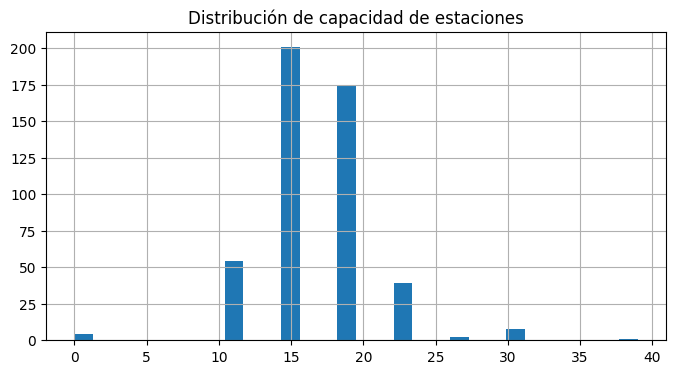

In [18]:
stations["dpcapacity"].hist(
    bins=30,
    figsize=(8,4)
)

plt.title("Distribución de capacidad de estaciones")
plt.show()

In [19]:
# Registros excluidos
raw_rows = 4497877
retained_rows = 4497119

excluded = raw_rows - retained_rows

print("Registros excluidos:", excluded)

pd.DataFrame({
    "concepto":[
        "crudos",
        "retenidos",
        "excluidos"
    ],
    "registros":[
        raw_rows,
        retained_rows,
        excluded
    ]
})



Registros excluidos: 758


,concepto,registros
0,crudos,4497877
1,retenidos,4497119
2,excluidos,758


## Conclusiones
- Se analizaron 12 meses consecutivos de información (2025-10 a 2026-09).
- La cobertura temporal es completa durante el periodo seleccionado.
- Existen patrones horarios claros tanto para salidas como para llegadas.
- La demanda varía entre estaciones.
- Las capacidades de las estaciones presentan variabilidad considerable.
- Solamente una fracción mínima de los registros fue excluida durante el proceso de limpieza.

## Implicaciones para Modelado
Las variables candidatas incluyen:

- hour
- day_of_week
- is_weekend
- month
- hour_sin
- hour_cos
- month_sin
- month_cos
- 
La variable objetivo para P1 será el conteo de salidas por estación en la siguiente hora.